# Köppen–Geiger a partir de estações INMET (BDMEP) — método do artigo original, dados atualizados

Terceira variante da análise: em vez de reanálise ERA5, reconstruímos aqui a
**mesma abordagem metodológica de Alvares et al. (2013)** — interpolação espacial a
partir de estações meteorológicas reais + modelo de elevação — mas com a rede de
estações **automáticas** do INMET (BDMEP), que é mais recente e ainda está em operação
(o artigo original usou a rede convencional, normais 1950–1990).

**Fonte dos dados**: 653 arquivos CSV baixados manualmente do portal BDMEP
(bdmep.inmet.gov.br), um por estação automática, cada um com temperatura média mensal
e precipitação total mensal, cobrindo principalmente 2000–2025 (a rede automática do
INMET é bem mais nova que a convencional).

**Método** (replicando o artigo o mais fielmente possível):
- **Temperatura**: regressão linear múltipla (latitude, longitude, altitude) sobre a
  climatologia mensal de cada estação, seguida de **krigagem ordinária dos resíduos**
  (regression-kriging) — mesmo espírito do modelo de Alvares et al. (2013) para
  temperatura, que usa altitude via SRTM.
- **Precipitação**: **krigagem ordinária** direta (com transformação log, já que a
  distribuição de chuva mensal é assimétrica — o próprio artigo relata a necessidade de
  transformação de dados via teste de Shapiro-Wilk), igual ao método do artigo.
- **Modelo de elevação**: ETOPO 2022 (NOAA), 1 arc-minuto (~1,8 km) — mais grosseiro que
  o SRTM 90m usado no artigo, mas obtido via um serviço público (ERDDAP) sem precisar
  baixar/mosaicar dezenas de tiles.
- **Malha de saída**: Brasil inteiro, grade regular 0,1°, recortada pela malha oficial
  do IBGE (mesma usada no `notebook_brasil.ipynb`).

**O algoritmo de classificação de Köppen (`koppen_classify`) é o mesmo dos outros dois
notebooks, copiado sem nenhuma alteração.**

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import geopandas as gpd
from shapely import contains_xy
from sklearn.linear_model import LinearRegression
from pykrige.ok import OrdinaryKriging
import glob
import os
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning, module="pykrige")
np.set_printoptions(suppress=True)

BDMEP_DIR = "data/bdmep_estacoes"
DEM_PATH = "data/etopo2022_60s_brasil.nc"
MIN_ANOS_POR_MES = 5  # minimo de anos validos em CADA mes-calendario para a estacao entrar


## 1. Ler e filtrar as estações (BDMEP)

Cada CSV traz 8 linhas de metadados (nome, código, lat/lon/altitude, situação, período)
seguidas de uma tabela mensal (`Data Medicao;PRECIPITACAO TOTAL, MENSAL (AUT)(mm);
TEMPERATURA MEDIA, MENSAL (AUT)(°C)`). Calculamos a climatologia mensal (média por
mês-calendário sobre os anos disponíveis) por estação, e **só mantemos estações com
pelo menos `MIN_ANOS_POR_MES` = 5 anos de dado válido em TODOS os 12 meses** — evita
que uma estação recém-instalada (com só 1-2 meses de histórico) distorça a
climatologia.

In [2]:
def parse_estacao(path):
    with open(path, encoding="utf-8") as f:
        linhas = f.readlines()
    meta = {}
    for linha in linhas[:8]:
        if ":" in linha:
            k, v = linha.split(":", 1)
            meta[k.strip()] = v.strip()
    idx_cabecalho = next(i for i, l in enumerate(linhas) if l.startswith("Data Medicao"))
    df = pd.read_csv(path, sep=";", skiprows=idx_cabecalho, encoding="utf-8", decimal=",",
                      na_values=["null", ""])
    df = df.dropna(axis=1, how="all")
    df.columns = [c.strip() for c in df.columns]
    return meta, df


arquivos = sorted(glob.glob(os.path.join(BDMEP_DIR, "dados_*.csv")))
print(f"Arquivos de estação encontrados: {len(arquivos)}")

linhas_climatologia = []
descartadas_sem_coluna = 0
descartadas_pouco_dado = 0

for path in arquivos:
    meta, df = parse_estacao(path)
    col_p = [c for c in df.columns if "PRECIPITACAO" in c]
    col_t = [c for c in df.columns if "TEMPERATURA" in c]
    if not col_p or not col_t:
        descartadas_sem_coluna += 1
        continue

    df["Data Medicao"] = pd.to_datetime(df["Data Medicao"])
    df["mes"] = df["Data Medicao"].dt.month
    df = df.rename(columns={col_p[0]: "precip", col_t[0]: "temp"})

    clim = df.groupby("mes")[["precip", "temp"]].agg(["mean", "count"])
    if clim[("precip", "count")].min() < MIN_ANOS_POR_MES or clim[("temp", "count")].min() < MIN_ANOS_POR_MES:
        descartadas_pouco_dado += 1
        continue

    linhas_climatologia.append({
        "codigo": meta["Codigo Estacao"], "nome": meta["Nome"],
        "lat": float(meta["Latitude"]), "lon": float(meta["Longitude"]), "alt": float(meta["Altitude"]),
        **{f"precip_{m}": clim.loc[m, ("precip", "mean")] for m in range(1, 13)},
        **{f"temp_{m}": clim.loc[m, ("temp", "mean")] for m in range(1, 13)},
    })

estacoes = pd.DataFrame(linhas_climatologia)
print(f"Descartadas (sem coluna de precip/temp): {descartadas_sem_coluna}")
print(f"Descartadas (< {MIN_ANOS_POR_MES} anos em algum mês): {descartadas_pouco_dado}")
print(f"Estações utilizáveis: {len(estacoes)}")
estacoes.describe()[["lat", "lon", "alt"]]


Arquivos de estação encontrados: 653


Descartadas (sem coluna de precip/temp): 22
Descartadas (< 5 anos em algum mês): 119
Estações utilizáveis: 512


,lat,lon,alt
count,512.000000,512.000000,512.000000
mean,-16.237407,-47.645710,425.406875
std,8.244334,6.611818,348.418515
min,-33.742222,-70.343611,2.000000
25%,-22.454722,-52.178750,116.157500
50%,-16.816944,-47.926667,375.935000
75%,-9.412292,-42.430764,662.382500
max,3.813611,-34.850833,1790.380000


## 2. Análise exploratória das estações

Antes de interpolar, olhamos a cobertura espacial da rede (onde há estações, onde há
buracos) e a distribuição de altitude — informação nova que o ERA5 não usa diretamente
neste projeto.

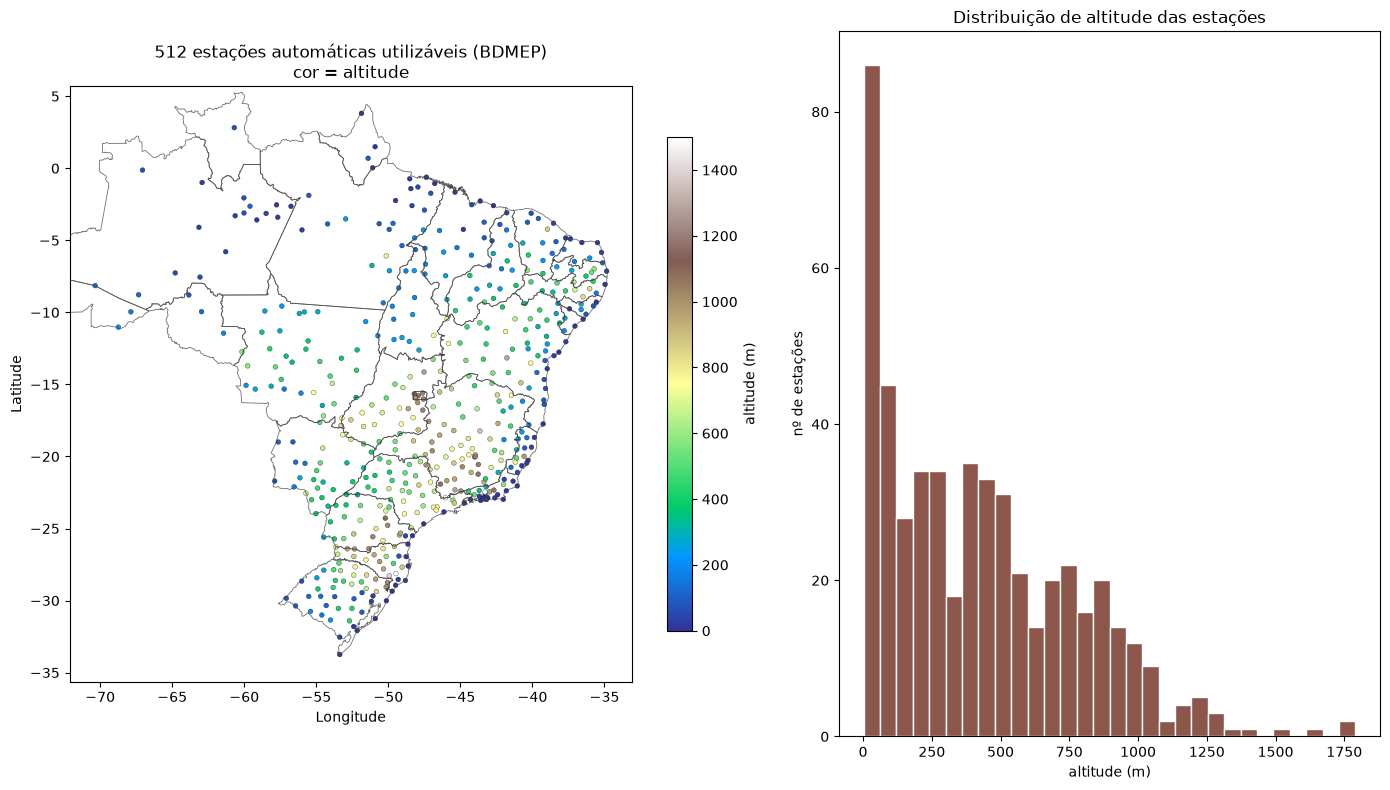

In [3]:
# Contorno dos estados (mesmo arquivo/função dos outros dois notebooks) e do país (IBGE)
BR_STATES = gpd.read_file("data/brazil_states.geojson")
BR_STATES["geometry"] = BR_STATES.geometry.simplify(0.03, preserve_topology=True)


def add_state_borders(ax, color="#404040", lw=0.6, alpha=0.75):
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    BR_STATES.boundary.plot(ax=ax, color=color, linewidth=lw, alpha=alpha, zorder=5)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


BR_COUNTRY = gpd.read_file("data/brasil_ibge.geojson")
BR_COUNTRY_GEOM = BR_COUNTRY.union_all()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1.3, 1]})

sc = axes[0].scatter(estacoes["lon"], estacoes["lat"], c=estacoes["alt"], cmap="terrain",
                      s=12, edgecolor="black", linewidth=0.2, vmin=0, vmax=1500)
add_state_borders(axes[0])
axes[0].set_aspect("equal")
axes[0].set_title(f"{len(estacoes)} estações automáticas utilizáveis (BDMEP)\ncor = altitude")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.colorbar(sc, ax=axes[0], label="altitude (m)", shrink=0.7)

axes[1].hist(estacoes["alt"], bins=30, color="tab:brown", edgecolor="white")
axes[1].set_title("Distribuição de altitude das estações")
axes[1].set_xlabel("altitude (m)")
axes[1].set_ylabel("nº de estações")

plt.tight_layout()
plt.show()


## 3. Grade de saída (Brasil inteiro, 0,1°) e altitude (ETOPO 2022)

Mesma lógica de recorte do `notebook_brasil.ipynb` (ponto-em-polígono contra a malha do
IBGE), mas numa grade mais fina (0,1°, ~11 km) já que a fonte agora é estação real, não
uma reanálise já grosseira. A altitude de cada célula vem do ETOPO 2022 (NOAA, 1
arc-minuto ≈ 1,8 km), obtido via o serviço público ERDDAP recortado para a bbox do
Brasil — mais grosseiro que o SRTM 90m do artigo original, mas suficiente para uma
grade de 0,1°.

In [4]:
lat_grid = np.arange(5.3, -33.9, -0.1)
lon_grid = np.arange(-74.0, -34.7, 0.1)
LON2D, LAT2D = np.meshgrid(lon_grid, lat_grid)

brasil_mask = contains_xy(BR_COUNTRY_GEOM, LON2D, LAT2D)
print(f"Grade total: {brasil_mask.size} células ({len(lat_grid)} lat × {len(lon_grid)} lon, 0.1°)")
print(f"Células dentro do Brasil (IBGE): {brasil_mask.sum()} ({100*brasil_mask.sum()/brasil_mask.size:.1f}%)")

# pontos-alvo (so as celulas dentro do Brasil -- e o que interessa para a krigagem)
lat_pts = LAT2D[brasil_mask]
lon_pts = LON2D[brasil_mask]

# altitude de cada ponto-alvo, via ETOPO 2022 (interpolacao bilinear da grade de 1 arc-min)
dem = xr.open_dataset(DEM_PATH)
dem = dem.assign_coords(longitude=(((dem.longitude + 180) % 360) - 180)).sortby("longitude")
alt_pts = dem["z"].interp(
    latitude=xr.DataArray(lat_pts, dims="pts"),
    longitude=xr.DataArray(lon_pts, dims="pts"),
    method="linear",
).values
alt_pts = np.clip(alt_pts, 0, None)  # altitude negativa (abaixo do nivel do mar) nao faz sentido em terra

print(f"Altitude na grade: min={alt_pts.min():.0f}m  max={alt_pts.max():.0f}m  média={alt_pts.mean():.0f}m")
print(f"NaN na altitude: {np.isnan(alt_pts).sum()}")


Grade total: 154056 células (392 lat × 393 lon, 0.1°)
Células dentro do Brasil (IBGE): 70934 (46.0%)


Altitude na grade: min=0m  max=2248m  média=318m
NaN na altitude: 0


## 4. Interpolação espacial (regressão + krigagem), mês a mês

- **Temperatura**: `T ~ lat + lon + altitude` (regressão linear, `sklearn`), depois
  krigagem ordinária dos resíduos (`pykrige`, modelo esférico — mesmo modelo que o
  artigo achou como melhor ajuste pra precipitação, Tabela 2 do artigo) e soma da
  tendência com o resíduo interpolado.
- **Precipitação**: krigagem ordinária direta sobre `log1p(precipitação)` (estabiliza a
  assimetria da distribuição de chuva), depois `expm1` pra voltar à escala original.
- Krigagem feita em graus de latitude/longitude (`coordinates_type="geographic"`),
  igual à abordagem do artigo (Tabela 2 reporta o alcance dos semivariogramas em graus).

In [5]:
T_full = np.full((12, len(lat_grid), len(lon_grid)), np.nan)
P_full = np.full((12, len(lat_grid), len(lon_grid)), np.nan)
X_grid = np.column_stack([lat_pts, lon_pts, alt_pts])

diagnosticos = []
for m in range(1, 13):
    y_t = estacoes[f"temp_{m}"].values
    y_p = estacoes[f"precip_{m}"].values
    X = estacoes[["lat", "lon", "alt"]].values

    # --- temperatura: regressao lat/lon/alt + krigagem dos residuos ---
    reg = LinearRegression().fit(X, y_t)
    resid = y_t - reg.predict(X)
    r2_temp = reg.score(X, y_t)
    rmse_temp = np.sqrt(np.mean(resid ** 2))

    trend_grid = reg.predict(X_grid)
    ok_resid = OrdinaryKriging(estacoes["lon"].values, estacoes["lat"].values, resid,
                                variogram_model="spherical", coordinates_type="geographic")
    resid_grid, _ = ok_resid.execute("points", lon_pts, lat_pts)
    temp_grid_pts = trend_grid + resid_grid

    # --- precipitacao: krigagem direta (log1p) ---
    p_log = np.log1p(y_p)
    ok_p = OrdinaryKriging(estacoes["lon"].values, estacoes["lat"].values, p_log,
                            variogram_model="spherical", coordinates_type="geographic")
    p_log_grid, _ = ok_p.execute("points", lon_pts, lat_pts)
    precip_grid_pts = np.clip(np.expm1(p_log_grid), 0, None)

    T_full[m - 1][brasil_mask] = temp_grid_pts
    P_full[m - 1][brasil_mask] = precip_grid_pts

    diagnosticos.append({
        "mes": m,
        "R2_regressao_temp": round(r2_temp, 3),
        "RMSE_temp_C": round(rmse_temp, 2),
        "alcance_variog_resid_temp_graus": round(ok_resid.variogram_model_parameters[1], 2),
        "alcance_variog_precip_graus": round(ok_p.variogram_model_parameters[1], 2),
    })
    print(f"mês {m:2d}/12 concluído -- R² temp={r2_temp:.3f}  RMSE temp={rmse_temp:.2f}°C")

diag_df = pd.DataFrame(diagnosticos)
diag_df


mês  1/12 concluído -- R² temp=0.772  RMSE temp=1.01°C


mês  2/12 concluído -- R² temp=0.770  RMSE temp=0.99°C


mês  3/12 concluído -- R² temp=0.750  RMSE temp=1.16°C


mês  4/12 concluído -- R² temp=0.799  RMSE temp=1.32°C


mês  5/12 concluído -- R² temp=0.878  RMSE temp=1.39°C


...

mês  9/12 concluído -- R² temp=0.715  RMSE temp=2.21°C


mês 10/12 concluído -- R² temp=0.705  RMSE temp=1.99°C


mês 11/12 concluído -- R² temp=0.772  RMSE temp=1.46°C


mês 12/12 concluído -- R² temp=0.763  RMSE temp=1.18°C


,mes,R2_regressao_temp,RMSE_temp_C,alcance_variog_resid_temp_graus,alcance_variog_precip_graus
0,1,0.772,1.01,12.33,32.58
1,2,0.770,0.99,11.42,32.58
2,3,0.750,1.16,9.36,32.58
3,4,0.799,1.32,9.54,32.58
4,5,0.878,1.39,15.73,10.15
5,6,0.882,1.52,19.09,9.63
6,7,0.869,1.64,32.58,9.76
7,8,0.819,1.88,19.30,10.93
8,9,0.715,2.21,12.14,28.58
9,10,0.705,1.99,9.40,32.41


## 5. Climatologia espacial resultante

Temperatura média anual e precipitação total anual, com as estações sobrepostas
(pontos) para conferir visualmente se a superfície interpolada é consistente com o
dado observado.

/tmp/ipykernel_39113/2624066062.py:1: RuntimeWarning: Mean of empty slice
  mat_map = np.nanmean(T_full, axis=0)


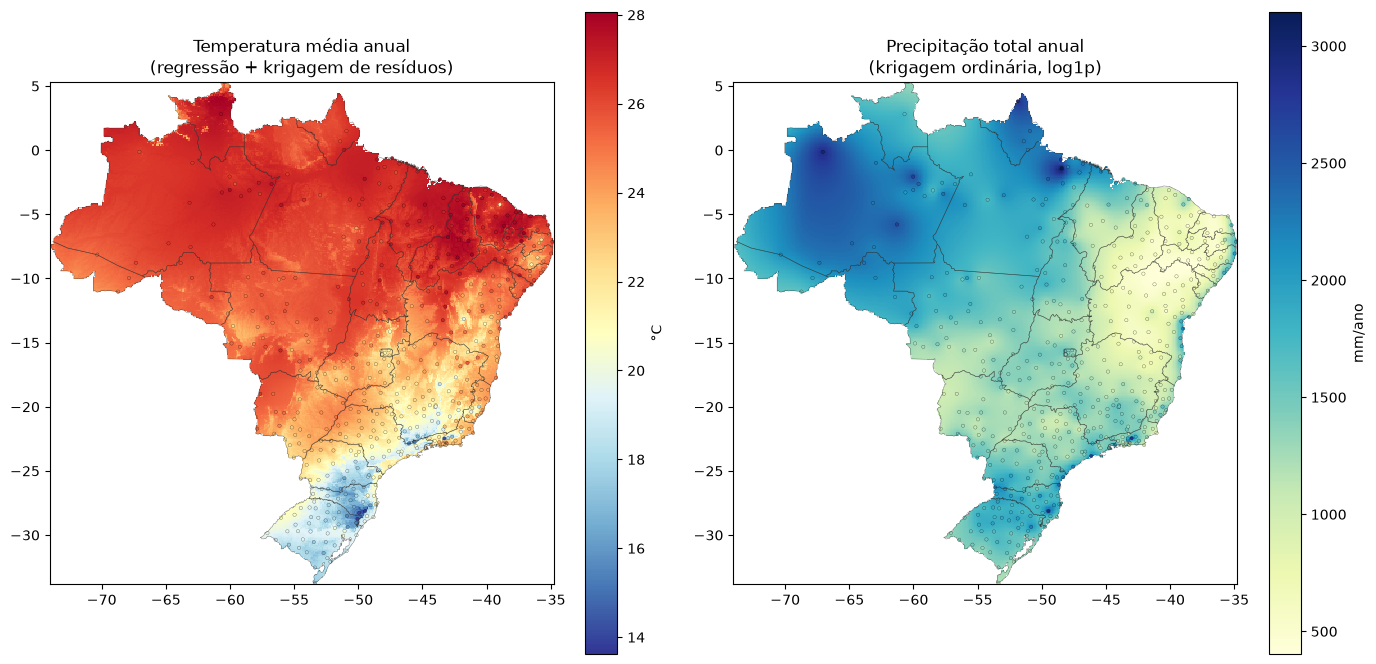

In [6]:
mat_map = np.nanmean(T_full, axis=0)
map_map = np.nansum(P_full, axis=0)
map_map[np.isnan(T_full[0])] = np.nan  # garante mascara consistente (fora do Brasil = NaN)

estacoes_mat = estacoes[[f"temp_{m}" for m in range(1, 13)]].mean(axis=1)
estacoes_map = estacoes[[f"precip_{m}" for m in range(1, 13)]].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 11))

im0 = axes[0].pcolormesh(lon_grid, lat_grid, mat_map, cmap="RdYlBu_r", shading="auto")
axes[0].scatter(estacoes["lon"], estacoes["lat"], c=estacoes_mat, cmap="RdYlBu_r",
                 s=6, edgecolor="black", linewidth=0.15, vmin=np.nanmin(mat_map), vmax=np.nanmax(mat_map))
fig.colorbar(im0, ax=axes[0], label="°C", shrink=0.6)
axes[0].set_title("Temperatura média anual\n(regressão + krigagem de resíduos)")
add_state_borders(axes[0], color="#333333", lw=0.4, alpha=0.6)
axes[0].set_aspect("equal")

im1 = axes[1].pcolormesh(lon_grid, lat_grid, map_map, cmap="YlGnBu", shading="auto")
axes[1].scatter(estacoes["lon"], estacoes["lat"], c=estacoes_map, cmap="YlGnBu",
                 s=6, edgecolor="black", linewidth=0.15, vmin=np.nanmin(map_map), vmax=np.nanmax(map_map))
fig.colorbar(im1, ax=axes[1], label="mm/ano", shrink=0.6)
axes[1].set_title("Precipitação total anual\n(krigagem ordinária, log1p)")
add_state_borders(axes[1], color="#333333", lw=0.4, alpha=0.6)
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()


## 6. Algoritmo de classificação de Köppen–Geiger

**Função copiada, caractere por caractere, do notebook original** (mesma que os outros
dois notebooks usam) — sem nenhuma alteração. Os mesmos 15 testes sintéticos são
reexecutados logo abaixo.

In [7]:
def koppen_classify(T, P, summer_idx=(9, 10, 11, 0, 1, 2), winter_idx=(3, 4, 5, 6, 7, 8)):
    """
    T, P: arrays (12, lat, lon) com climatologia mensal de temperatura (°C) e
          precipitacao (mm/mes), mes 0 = Janeiro ... mes 11 = Dezembro.
    summer_idx / winter_idx: indices de mes (0-based) do semestre de verao e inverno
          para o hemisferio da regiao (default: hemisferio sul).
    Retorna: array 2D de strings com o codigo Koppen (ex: 'Aw', 'Cfa', 'BSh', ...).
             Celulas sem dado valido (oceano/mascara) recebem 'NA'.
    """
    T = np.asarray(T)
    P = np.asarray(P)

    # celulas com qualquer mes faltante (ex: oceano dentro da bbox) ficam de fora
    valid = ~(np.isnan(T).any(axis=0) | np.isnan(P).any(axis=0))

    MAT = T.mean(axis=0)
    MAP = P.sum(axis=0)
    Tcold = T.min(axis=0)
    Thot = T.max(axis=0)
    Pdry = P.min(axis=0)
    TM10 = (T > 10).sum(axis=0)

    Psum = P[list(summer_idx)]
    Pwin = P[list(winter_idx)]
    Psdry, Pswet = Psum.min(axis=0), Psum.max(axis=0)
    Pwdry, Pwwet = Pwin.min(axis=0), Pwin.max(axis=0)

    frac_win = Pwin.sum(axis=0) / MAP
    frac_sum = Psum.sum(axis=0) / MAP
    Pthresh = np.where(frac_win >= 0.7, 2 * MAT,
                        np.where(frac_sum >= 0.7, 2 * MAT + 28, 2 * MAT + 14))

    code = np.full(MAT.shape, "NA", dtype="<U3")
    unresolved = valid.copy()

    # --- B: clima arido (checado primeiro, tem prioridade sobre A/C/D) ---
    is_B = unresolved & (MAP < 10 * Pthresh)
    is_h = MAT >= 18
    is_arid = is_B & (MAP < 5 * Pthresh)
    is_semiarid = is_B & ~is_arid
    code[is_arid & is_h] = "BWh"
    code[is_arid & ~is_h] = "BWk"
    code[is_semiarid & is_h] = "BSh"
    code[is_semiarid & ~is_h] = "BSk"
    unresolved &= ~is_B

    # --- A: clima tropical ---
    is_A = unresolved & (Tcold >= 18)
    is_Af = is_A & (Pdry >= 60)
    is_Am = is_A & ~is_Af & (Pdry >= (100 - MAP / 25))
    is_Aws = is_A & ~is_Af & ~is_Am
    dry_month = np.argmin(P, axis=0)
    dry_in_summer = np.isin(dry_month, list(summer_idx))
    is_As = is_Aws & dry_in_summer
    is_Aw = is_Aws & ~dry_in_summer
    code[is_Af] = "Af"
    code[is_Am] = "Am"
    code[is_As] = "As"
    code[is_Aw] = "Aw"
    unresolved &= ~is_A

    # --- E: clima polar ---
    is_E = unresolved & (Thot < 10)
    code[is_E & (Thot >= 0)] = "ET"
    code[is_E & (Thot < 0)] = "EF"
    unresolved &= ~is_E

    # --- C / D: temperado / continental ---
    is_CD = unresolved
    is_D = is_CD & (Tcold < -3)
    is_C = is_CD & ~is_D

    is_f = is_CD & (Pdry > 40)
    is_w = is_CD & ~is_f & (Pswet >= 10 * Pwdry)
    is_s = is_CD & ~is_f & ~is_w & (Pwwet >= 3 * Psdry)
    # fallback: quando nao se enquadra perfeitamente em w/s mas Pdry<=40, classifica como f
    # (evita celulas sem classificacao por empates nas condicoes de fronteira)
    is_unclassified_rain = is_CD & ~is_f & ~is_w & ~is_s
    is_f = is_f | is_unclassified_rain

    is_a = is_CD & (Thot >= 22)
    is_b = is_CD & (Thot < 22) & (TM10 >= 4)
    is_c = is_CD & (Thot < 22) & (TM10 < 4) & (Tcold >= -38)
    is_d = is_CD & (Tcold < -38)

    for zone_mask, zone_letter in [(is_C, "C"), (is_D, "D")]:
        for rain_mask, rain_letter in [(is_f, "f"), (is_w, "w"), (is_s, "s")]:
            m = zone_mask & rain_mask
            code[m & is_a] = zone_letter + rain_letter + "a"
            code[m & is_b] = zone_letter + rain_letter + "b"
            code[m & is_c] = zone_letter + rain_letter + "c"
            if zone_letter == "D":
                code[m & is_d] = zone_letter + rain_letter + "d"

    assert (code[~valid] == "NA").all()
    assert (code[valid] != "NA").all(), "existem celulas com dado valido que nao foram classificadas"
    return code, valid


In [8]:
def _classify_profile(T12, P12):
    """Classifica um unico perfil mensal (listas de 12 valores)."""
    T = np.array(T12, dtype=float).reshape(12, 1, 1)
    P = np.array(P12, dtype=float).reshape(12, 1, 1)
    return koppen_classify(T, P)[0][0, 0]


# Perfis sinteticos (hemisferio sul: verao = out-mar, inverno = abr-set).
# Jan .......................................................... Dez
CASOS_TESTE = {
    "Af":  ([27] * 12,
            [280, 280, 300, 300, 300, 160, 120, 80, 100, 140, 180, 220]),
    "Am":  ([27] * 12,
            [300, 350, 400, 400, 380, 250, 130, 40, 15, 30, 80, 150]),
    "Aw":  ([26] * 12,
            [280, 260, 270, 150, 40, 2, 1, 5, 40, 180, 230, 250]),
    "As":  ([26] * 12,          # seca no verao (set-dez), chuva no inverno
            [60, 90, 150, 200, 250, 280, 220, 110, 30, 20, 25, 40]),
    "BSh": ([26] * 12,
            [80, 110, 130, 60, 20, 5, 2, 1, 2, 10, 30, 60]),
    "BWh": ([28] * 12,
            [5, 5, 3, 2, 1, 0, 0, 0, 1, 2, 3, 5]),
    "Cfa": ([24, 24, 22, 19, 16, 13, 13, 14, 16, 19, 21, 23],
            [120, 130, 130, 140, 120, 140, 130, 140, 140, 120, 110, 120]),
    "Cfb": ([20.5, 20, 19, 17, 14, 13, 13, 14, 15, 17, 18, 20],
            [170, 150, 130, 90, 100, 110, 100, 80, 120, 140, 120, 150]),
    "Cwa": ([23.5, 23.5, 23, 21, 19, 17.5, 17.5, 19, 21, 22, 23, 23],
            [280, 200, 160, 60, 40, 20, 15, 20, 50, 130, 180, 260]),
    "Cwb": ([21.5, 21.5, 21, 20, 18, 16.5, 15.5, 17, 19, 20, 21, 21],
            [300, 180, 150, 60, 25, 12, 10, 12, 35, 120, 220, 300]),
    "Cwc": ([11.5, 11, 9.5, 8, 6, 4.5, 4.5, 6, 8, 9.5, 10, 11],   # so 3 meses > 10 C
            [200, 160, 150, 60, 40, 20, 15, 25, 60, 140, 180, 210]),
    "Csa": ([22.7, 22.5, 22, 21, 19, 18, 17.5, 17.9, 19, 20.5, 22, 22.7],
            [40, 60, 80, 120, 140, 130, 100, 50, 25, 20, 20, 25]),
    "Csb": ([21.5, 21.3, 21, 20, 19, 17.5, 17, 17.5, 18.5, 19.5, 20.5, 21.5],
            [40, 60, 80, 120, 140, 130, 100, 50, 25, 20, 20, 25]),
    "ET":  ([5, 5, 4, 2, 0, -2, -3, -1, 1, 3, 4, 5], [50] * 12),
    "EF":  ([-5] * 12, [30] * 12),
}

falhas = []
for esperado, (T12, P12) in CASOS_TESTE.items():
    obtido = _classify_profile(T12, P12)
    if obtido != esperado:
        falhas.append((esperado, obtido))
    print(f"{'OK   ' if obtido == esperado else 'FALHA'} esperado={esperado:<4} obtido={obtido:<4}"
          f"  Tcold={min(T12):5.1f}  Thot={max(T12):5.1f}  MAP={sum(P12):5.0f}mm  Pdry={min(P12):3.0f}mm")

assert not falhas, f"casos que falharam: {falhas}"
print(f"\n{len(CASOS_TESTE)}/{len(CASOS_TESTE)} casos corretos -- algoritmo idêntico aos outros dois notebooks")


OK    esperado=Af   obtido=Af    Tcold= 27.0  Thot= 27.0  MAP= 2460mm  Pdry= 80mm
OK    esperado=Am   obtido=Am    Tcold= 27.0  Thot= 27.0  MAP= 2525mm  Pdry= 15mm
OK    esperado=Aw   obtido=Aw    Tcold= 26.0  Thot= 26.0  MAP= 1708mm  Pdry=  1mm
OK    esperado=As   obtido=As    Tcold= 26.0  Thot= 26.0  MAP= 1475mm  Pdry= 20mm
OK    esperado=BSh  obtido=BSh   Tcold= 26.0  Thot= 26.0  MAP=  510mm  Pdry=  1mm
OK    esperado=BWh  obtido=BWh   Tcold= 28.0  Thot= 28.0  MAP=   27mm  Pdry=  0mm
OK    esperado=Cfa  obtido=Cfa   Tcold= 13.0  Thot= 24.0  MAP= 1540mm  Pdry=110mm
OK    esperado=Cfb  obtido=Cfb   Tcold= 13.0  Thot= 20.5  MAP= 1460mm  Pdry= 80mm
OK    esperado=Cwa  obtido=Cwa   Tcold= 17.5  Thot= 23.5  MAP= 1415mm  Pdry= 15mm
OK    esperado=Cwb  obtido=Cwb   Tcold= 15.5  Thot= 21.5  MAP= 1424mm  Pdry= 10mm
OK    esperado=Cwc  obtido=Cwc   Tcold=  4.5  Thot= 11.5  MAP= 1260mm  Pdry= 15mm
OK    esperado=Csa  obtido=Csa   Tcold= 17.5  Thot= 22.7  MAP=  810mm  Pdry= 20mm
OK    esperado=C

## 7. Classificação e mapa final

In [9]:
koppen_codes, valid_mask = koppen_classify(T_full, P_full)
territorio_mask = valid_mask & brasil_mask  # ja deveriam coincidir (T_full/P_full so tem dado dentro do Brasil)

print(f"Células com dado válido: {valid_mask.sum()}")
print(f"Células dentro do Brasil (IBGE): {brasil_mask.sum()}")
print(f"Interseção (classificadas): {territorio_mask.sum()}")

unique, counts = np.unique(koppen_codes[territorio_mask], return_counts=True)
tabela_koppen = pd.DataFrame({"climate": unique, "n_pixels": counts,
                               "%": 100 * counts / counts.sum()}).sort_values("%", ascending=False)
tabela_koppen


Células com dado válido: 70934
Células dentro do Brasil (IBGE): 70934
Interseção (classificadas): 70934


,climate,n_pixels,%
3,Aw,34709,48.931401
1,Am,14541,20.499337
0,Af,7340,10.347647
4,BSh,5590,7.880565
6,Cfa,4423,6.235374
2,As,1864,2.627795
7,Cfb,1378,1.942651
8,Cwa,815,1.148955
9,Cwb,269,0.379226
5,BWh,5,0.007049


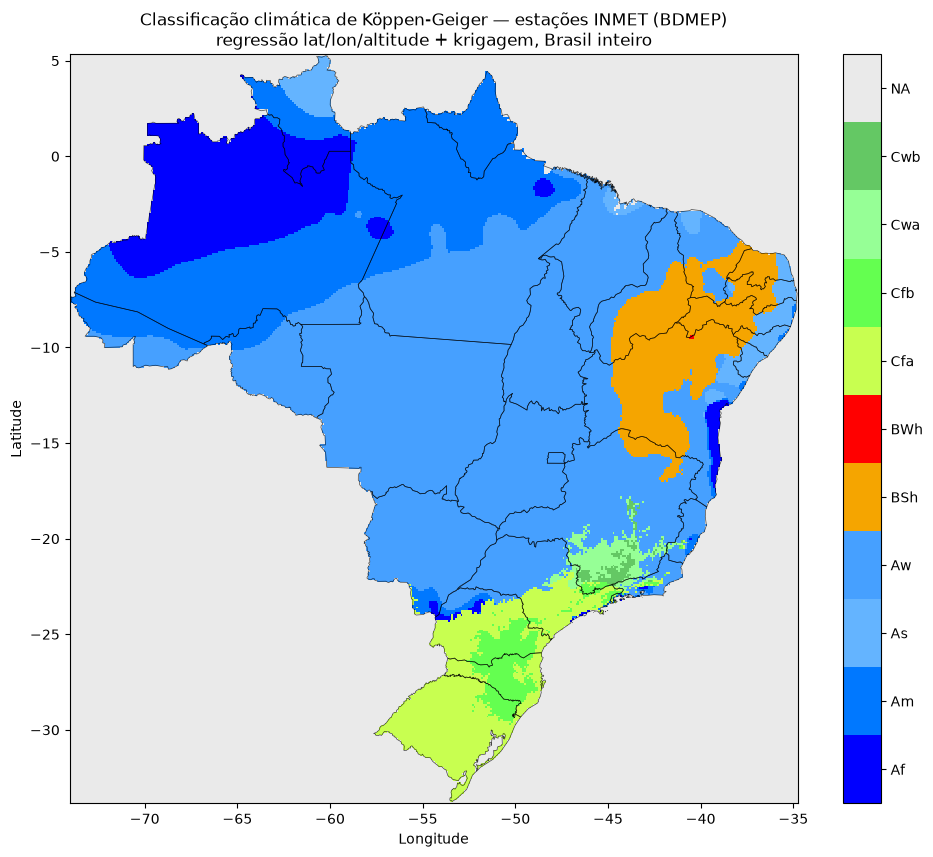

In [10]:
KOPPEN_COLORS = {
    "Af": "#0000FF", "Am": "#0078FF", "Aw": "#46A0FF", "As": "#64B4FF",
    "BWh": "#FF0000", "BWk": "#FFA0A0", "BSh": "#F5A500", "BSk": "#FFDC64",
    "Csa": "#FFFF00", "Csb": "#C8C800", "Csc": "#969600",
    "Cwa": "#96FF96", "Cwb": "#64C864", "Cwc": "#329632",
    "Cfa": "#C8FF50", "Cfb": "#64FF50", "Cfc": "#32C800",
    "Dsa": "#FF00FF", "Dsb": "#C800C8", "Dsc": "#963296", "Dsd": "#966496",
    "Dwa": "#ABB1FF", "Dwb": "#5A77DB", "Dwc": "#4C51B5", "Dwd": "#320087",
    "Dfa": "#00FFFF", "Dfb": "#37C8FF", "Dfc": "#007D7D", "Dfd": "#00465F",
    "ET": "#B3B3B3", "EF": "#696969",
    "NA": "#EAEAEA",
}

codes_brasil = np.where(territorio_mask, koppen_codes, "NA")
codes_present = sorted(np.unique(codes_brasil))
cmap = ListedColormap([KOPPEN_COLORS.get(c, "#FF00FF") for c in codes_present])
code_to_int = {c: i for i, c in enumerate(codes_present)}
int_grid = np.vectorize(code_to_int.get)(codes_brasil)

fig, ax = plt.subplots(figsize=(10, 11))
im = ax.pcolormesh(lon_grid, lat_grid, int_grid, cmap=cmap,
                    vmin=-0.5, vmax=len(codes_present) - 0.5, shading="auto")
ax.set_title("Classificação climática de Köppen-Geiger — estações INMET (BDMEP)\n"
              "regressão lat/lon/altitude + krigagem, Brasil inteiro")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
add_state_borders(ax, color="black", lw=0.5, alpha=0.7)

cbar = fig.colorbar(im, ax=ax, ticks=range(len(codes_present)), shrink=0.7)
cbar.ax.set_yticklabels(codes_present)

plt.tight_layout()
plt.show()


## 8. Comparação: artigo × ERA5 (whole-Brazil) × estações (este notebook)

Três fontes de dado completamente diferentes (normais de estação 1950–1990 com
krigagem+SRTM; reanálise ERA5 1996–2025; estações automáticas atuais com
krigagem+ETOPO) classificadas pelo **mesmo algoritmo**. As diferenças aqui são 100%
sobre dado de entrada.

In [11]:
zonas_validas = np.array([c[0] for c in codes_brasil[territorio_mask]])
unique_z, counts_z = np.unique(zonas_validas, return_counts=True)
tabela_zonas = pd.DataFrame({"zona": unique_z, "% estações (este notebook)": 100 * counts_z / counts_z.sum()})
tabela_zonas = tabela_zonas.set_index("zona")

artigo = pd.Series({"A": 81.4, "B": 4.9, "C": 13.7}, name="% artigo (Alvares et al. 2013)")
era5_brasil = pd.Series({"A": 82.3, "B": 8.2, "C": 9.5}, name="% ERA5 (notebook_brasil.ipynb)")

comparacao = tabela_zonas.join(artigo, how="outer").join(era5_brasil, how="outer").fillna(0).round(1)
comparacao


,% estações (este notebook),% artigo (Alvares et al. 2013),% ERA5 (notebook_brasil.ipynb)
zona,,,
A,82.4,81.4,82.3
B,7.9,4.9,8.2
C,9.7,13.7,9.5


## 9. Ressalvas metodológicas

O algoritmo passa nos mesmos 15/15 testes sintéticos dos outros dois notebooks — as
ressalvas abaixo são todas sobre os **dados de entrada e o método de interpolação**,
não sobre a classificação em si.

- **Rede mais nova e mais rala que a do artigo**: a rede automática do INMET começou a
  ser instalada por volta de 2000–2008 na maior parte do país; mesmo com o filtro de
  ≥5 anos por mês-calendário, a maioria das estações usadas tem 10-20 anos de histórico,
  não os >25 anos (1950–1990) do artigo. "Atualizado" aqui tem esse preço: menos anos
  de normal climatológica.
- **Densidade e distribuição desigual**: 512 estações usadas aqui vs. os 2.950 (chuva) e
  2.400 (temperatura) do artigo — quase 5x menos. A cobertura é boa nas regiões Sul/
  Sudeste/litoral, mas tem buracos grandes na Amazônia interior e em partes do Centro-
  Oeste, onde a krigagem se apoia quase só na tendência de regressão (lat/lon/altitude),
  sem correção local de resíduo por falta de estação por perto.
- **DEM mais grosseiro**: ETOPO 2022 a 1 arc-minuto (~1,8 km) vs. SRTM 90m do artigo —
  suficiente para captar o gradiente regional de altitude, mas ainda assim suaviza picos
  isolados (o teste de validação no início do processo mostrou o Pico da Bandeira ~470m
  abaixo do valor real).
- **R² da regressão de temperatura (~0,7-0,8, ver Seção 4) é menor que o artigo
  (R²=0,93, RMSE=0,80°C, segundo Alvares et al. 2013)** — nosso modelo é mais simples
  (regressão linear direta lat/lon/altitude por mês, sem os termos adicionais que o
  modelo deles provavelmente usa) e a base de estações é mais esparsa.
- **Krigagem em graus geográficos**: mesma escolha do artigo (Tabela 2 reporta alcances
  em graus), mas para uma área do tamanho do Brasil isso introduz alguma anisotropia
  não corrigida (1° de longitude "encolhe" fisicamente perto do equador comparado a
  perto do Trópico de Capricórnio) — o artigo não menciona ter corrigido isso
  explicitamente, então mantivemos a mesma simplificação.
- **Precipitação sem separação sazonal na escolha do modelo de variograma**: usamos
  sempre o modelo esférico (o que o artigo achou como melhor ajuste para as suas 2.950
  estações) sem testar outros modelos mês a mês — o artigo testou vários (esférico,
  exponencial, gaussiano, linear) e escolheu por mês; aqui fixamos esférico para todos
  os 12 meses por simplicidade.